- Invoice	
- StockCode	
- Description	
- Quantity	>0
- InvoiceDate	转换datetime
- Price	>0
- Customer ID	 去掉空白
- Country
- 添加：Quantity*Price=TotalPrice

In [112]:
import pandas as pd
import matplotlib.pyplot as plt
import platform

In [113]:
df = pd.read_excel('online_retail_II.xlsx')

In [114]:
df = df[df['Quantity'] > 0]                  # 去掉退货/取消
df = df[df['Price'] > 0]                     # 去掉单价为0或负值
df = df.dropna(subset=['Customer ID'])       # 去掉没有客户ID的记录
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])
df['TotalPrice'] = df['Quantity'] * df['Price']

In [115]:
print(f"数据加载完成，共 {len(df)} 条记录")
print(f"字段: {list(df.columns)}")
df[['InvoiceDate', 'Customer ID', 'Quantity', 'Price', 'TotalPrice', 'Country']].to_csv("cleaned_online_retail.csv", index=False, encoding="utf-8-sig")
print("✅ 已保存精简版数据")

数据加载完成，共 407664 条记录
字段: ['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'Customer ID', 'Country', 'TotalPrice']
✅ 已保存精简版数据


In [116]:
purchases = df.copy()

print(f"购买事件总数: {len(purchases):,}")
print(f"产生过购买的独立用户数: {purchases['Customer ID'].nunique():,}")
print(f"\n购买时间范围: {purchases['InvoiceDate'].min()} 到 {purchases['InvoiceDate'].max()}")
print(f"\n前 5 行:")
purchases[["InvoiceDate", "Customer ID", "Price"]].head()

购买事件总数: 407,664
产生过购买的独立用户数: 4,312

购买时间范围: 2009-12-01 07:45:00 到 2010-12-09 20:01:00

前 5 行:


,InvoiceDate,Customer ID,Price
0,2009-12-01 07:45:00,13085.0,6.95
1,2009-12-01 07:45:00,13085.0,6.75
2,2009-12-01 07:45:00,13085.0,6.75
3,2009-12-01 07:45:00,13085.0,2.10
4,2009-12-01 07:45:00,13085.0,1.25


In [117]:
#计算每个用户的 RFM 三个核心指标，为后续用户分层做准备
snapshot_date = pd.to_datetime("2010-12-10")
print(f"快照日: {snapshot_date}")
rfm = purchases.groupby("Customer ID").agg(
    last_purchase=("InvoiceDate", "max"),      
    frequency=("InvoiceDate", "count"),         
    monetary=("Price", "sum")                  
).reset_index()

rfm["recency"] = (snapshot_date - rfm["last_purchase"]).dt.days

rfm = rfm[["Customer ID", "recency", "frequency", "monetary"]]

print(f"\nRFM 表行数(= 购买用户数): {len(rfm):,}")
print(f"\n前 10 个用户:")
print(rfm.head(10).to_string(index=False))

print(f"\n三个指标的分布:")
print(rfm[["recency", "frequency", "monetary"]].describe())

快照日: 2010-12-10 00:00:00

RFM 表行数(= 购买用户数): 4,312

前 10 个用户:
 Customer ID  recency  frequency  monetary
     12346.0      164         33    206.36
     12347.0        2         71    162.95
     12348.0       73         20     14.39
     12349.0       42        102    875.34
     12351.0       10         21     49.46
     12352.0       10         18     54.60
     12353.0       43         20     38.78
     12355.0      202         22     52.78
     12356.0       15         84    261.38
     12357.0       23        165   1395.64

三个指标的分布:
           recency    frequency      monetary
count  4312.000000  4312.000000   4312.000000
mean     90.172542    94.541744    311.461917
std      96.861457   202.046410    863.827679
min       0.000000     1.000000      0.190000
25%      17.000000    18.000000     56.967500
50%      52.000000    44.000000    136.845000
75%     135.000000   102.000000    323.175000
max     373.000000  5570.000000  31567.340000


In [118]:
print("购买次数最多的 10 个用户:")
print(rfm.sort_values("frequency", ascending=False).head(10).to_string(index=False))

print("\n消费金额最高的 10 个用户:")
print(rfm.sort_values("monetary", ascending=False).head(10).to_string(index=False))

print("\nfrequency 各值的用户数量(前15):")
print(rfm["frequency"].value_counts().sort_index().head(15))

购买次数最多的 10 个用户:
 Customer ID  recency  frequency  monetary
     14911.0        0       5570  31567.34
     17841.0        0       5043  15215.85
     14606.0        1       3866  10980.09
     14156.0        6       2648  18695.87
     12748.0        0       2633   9346.60
     17850.0        7       2499   7655.89
     16549.0       32       2269   4723.07
     15311.0        0       2055   5906.84
     14646.0        9       1773   4259.99
     14527.0        0       1729   8806.64

消费金额最高的 10 个用户:
 Customer ID  recency  frequency  monetary
     14911.0        0       5570  31567.34
     14156.0        6       2648  18695.87
     17841.0        0       5043  15215.85
     15760.0      265          2  13916.34
     14063.0       73         40  13443.55
     14606.0        1       3866  10980.09
     12918.0      261          1  10953.50
     12748.0        0       2633   9346.60
     17949.0        6         87   9221.14
     14527.0        0       1729   8806.64

frequency 各值的用户数量(前1

In [119]:
rfm["R_score"] = pd.qcut(rfm["recency"].rank(method="first"), q=5, labels=[5, 4, 3, 2, 1]).astype(int)
rfm["M_score"] = pd.qcut(rfm["monetary"].rank(method="first"), q=5, labels=[1, 2, 3, 4, 5]).astype(int)
#rfm["F_score"] = pd.qcut(rfm["frequency"].rank(method="first"), q=5, labels=[1, 2, 3, 4, 5]).astype(int)


def frequency_score(f):
    if f >= 102:
        return 5
    elif f >= 44:
        return 4
    elif f >= 18:
        return 3
    elif f >= 5:
        return 2
    else:
        return 1
rfm["F_score"] = rfm["frequency"].apply(frequency_score)

print("打分后的前 10 个用户:")
print(rfm.head(10).to_string(index=False))

print("\n各分数档人数:")
for col in ["R_score", "F_score", "M_score"]:
    print(f"\n{col}:")
    print(rfm[col].value_counts().sort_index())

打分后的前 10 个用户:
 Customer ID  recency  frequency  monetary  R_score  M_score  F_score
     12346.0      164         33    206.36        2        4        3
     12347.0        2         71    162.95        5        3        4
     12348.0       73         20     14.39        2        1        3
     12349.0       42        102    875.34        3        5        5
     12351.0       10         21     49.46        5        2        3
     12352.0       10         18     54.60        5        2        3
     12353.0       43         20     38.78        3        1        3
     12355.0      202         22     52.78        1        2        3
     12356.0       15         84    261.38        4        4        4
     12357.0       23        165   1395.64        4        5        5

各分数档人数:

R_score:
R_score
1    863
2    862
3    862
4    862
5    863
Name: count, dtype: int64

F_score:
F_score
1     243
2     792
3    1111
4    1078
5    1088
Name: count, dtype: int64

M_score:
M_score
1    8

In [120]:
def segment_user(row):
    r = row["R_score"]
    f = row["F_score"]
    
    if r >= 3 and f >= 3:
        return "高价值用户"      
    elif r >= 3 and f < 3:
        return "新客户" 
    elif r < 3 and f >= 3:
        return "沉睡用户"        
    else:
        return "流失用户"       

rfm["segment"] = rfm.apply(segment_user, axis=1)

print("用户分层结果:")
seg_counts = rfm["segment"].value_counts()
seg_pct = (rfm["segment"].value_counts(normalize=True) * 100).round(1)

summary = pd.DataFrame({
    "人数": seg_counts,
    "占比(%)": seg_pct
})
print(summary.to_string())
print("\n各层的平均特征:")
seg_profile = rfm.groupby("segment").agg(
    用户数=("Customer ID", "count"),
    平均recency=("recency", "mean"),
    平均frequency=("frequency", "mean"),
    平均monetary=("monetary", "mean")
).round(1)
print(seg_profile.to_string())

用户分层结果:
           人数  占比(%)
segment             
高价值用户    2192   50.8
沉睡用户     1085   25.2
流失用户      640   14.8
新客户       395    9.2

各层的平均特征:
          用户数  平均recency  平均frequency  平均monetary
segment                                          
新客户       395       34.9          9.6        54.1
沉睡用户     1085      169.6         61.7       212.9
流失用户      640      211.7          8.6        87.2
高价值用户    2192       25.4        151.2       472.1


In [121]:
if platform.system() == "Windows":
    plt.rcParams["font.sans-serif"] = ["SimHei", "Microsoft YaHei"]
elif platform.system() == "Darwin":
    plt.rcParams["font.sans-serif"] = ["PingFang SC", "Heiti SC", "Arial Unicode MS"]
plt.rcParams["axes.unicode_minus"] = False

print("✅ 中文设置完成")

✅ 中文设置完成


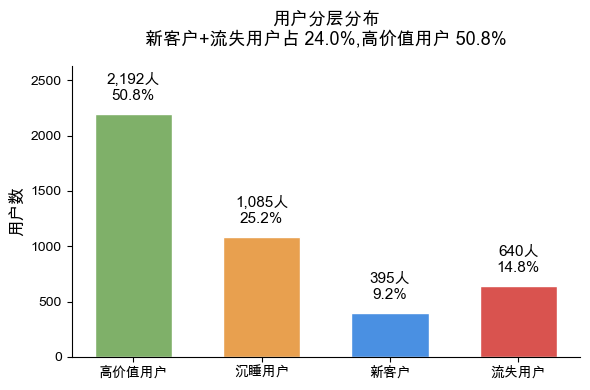

✅ 已保存 fig1_user_segments.png


In [122]:
order = ["高价值用户", "沉睡用户", "新客户", "流失用户"]
seg_counts = rfm["segment"].value_counts().reindex(order)
seg_pct = (seg_counts / seg_counts.sum() * 100).round(1)

colors = ["#7FB069", "#E8A04F", "#4A90E2", "#D9534F"]

fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(order, seg_counts.values, color=colors, edgecolor="white", width=0.6)

for bar, count, pct in zip(bars, seg_counts.values, seg_pct.values):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 100,
            f"{count:,}人\n{pct}%", ha="center", va="bottom", fontsize=11, fontweight="bold")

ax.set_ylabel("用户数", fontsize=12)
ax.set_ylim(0, max(seg_counts.values) * 1.2)
for side in ["top", "right"]:
    ax.spines[side].set_visible(False)

ax.set_title("用户分层分布\n新客户+流失用户占 24.0%,高价值用户 50.8%",
             fontsize=13, pad=15)

plt.tight_layout()
plt.savefig("fig1_user_segments.png", dpi=150, bbox_inches="tight")
plt.show()
print("✅ 已保存 fig1_user_segments.png")

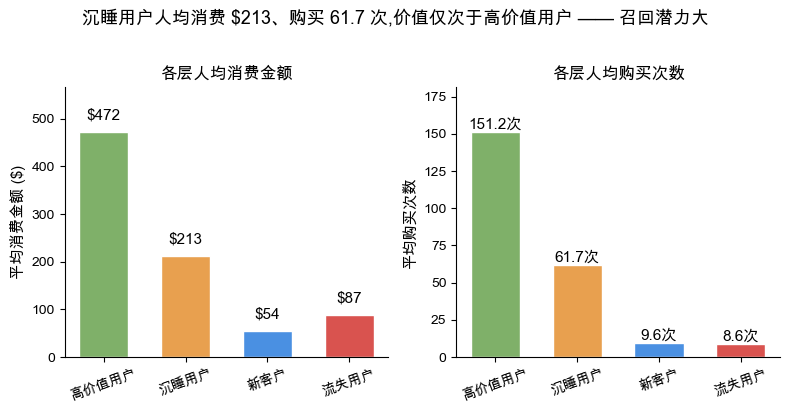

✅ 已保存 fig2_segment_value.png


In [123]:
order = ["高价值用户", "沉睡用户", "新客户", "流失用户"]
profile = rfm.groupby("segment").agg(
    avg_monetary=("monetary", "mean"),
    avg_frequency=("frequency", "mean")
).reindex(order)

colors = ["#7FB069", "#E8A04F", "#4A90E2", "#D9534F"]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(8, 4))
bars1 = ax1.bar(order, profile["avg_monetary"].values, color=colors, edgecolor="white", width=0.6)
for bar, val in zip(bars1, profile["avg_monetary"].values):
    ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 20,
             f"${val:.0f}", ha="center", va="bottom", fontsize=11, fontweight="bold")
ax1.set_ylabel("平均消费金额 ($)", fontsize=11)
ax1.set_title("各层人均消费金额", fontsize=12)
ax1.set_ylim(0, max(profile["avg_monetary"].values) * 1.2)
for side in ["top", "right"]:
    ax1.spines[side].set_visible(False)
ax1.tick_params(axis="x", labelrotation=20)
bars2 = ax2.bar(order, profile["avg_frequency"].values, color=colors, edgecolor="white", width=0.6)
for bar, val in zip(bars2, profile["avg_frequency"].values):
    ax2.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.1,
             f"{val:.1f}次", ha="center", va="bottom", fontsize=11, fontweight="bold")
ax2.set_ylabel("平均购买次数", fontsize=11)
ax2.set_title("各层人均购买次数", fontsize=12)
ax2.set_ylim(0, max(profile["avg_frequency"].values) * 1.2)
for side in ["top", "right"]:
    ax2.spines[side].set_visible(False)
ax2.tick_params(axis="x", labelrotation=20)

fig.suptitle("沉睡用户人均消费 $213、购买 61.7 次,价值仅次于高价值用户 —— 召回潜力大",
             fontsize=13, y=1.02)

plt.tight_layout()
plt.savefig("fig2_segment_value.png", dpi=150, bbox_inches="tight")
plt.show()
print("✅ 已保存 fig2_segment_value.png")